# Crecimiento tumoral: tres modelos para el diámetro

El tamaño de un tumor sólido se mide con calibrador o con imagen: se registra un diámetro característico $d(t)$ en mm y, suponiendo simetría esférica, el volumen es $V = \frac{\pi}{6}d^3$. Comparamos tres modelos clásicos:

| Modelo | Ecuación | Solución |
|---|---|---|
| Lineal | $\dot d = k$ | $d(t) = d_0 + kt$ |
| Exponencial | $\dot d = \lambda d$ | $d(t) = d_0 e^{\lambda t}$ |
| Gompertz | $\dot d = a\,d\ln(K_d/d)$ | $d(t) = K_d\left(d_0/K_d\right)^{e^{-at}}$ |

**Sobre los datos.** El enunciado sugiere descargar el conjunto de Benzekry et al. (2014) de Zenodo (carcinoma pulmonar de Lewis, 20 ratones, días 4–22). Al preparar esta entrada no pudimos descargarlo, así que en la sección 3 usamos **datos simulados** con la misma estructura (20 ratones, volúmenes en mm³ medidos entre los días 4 y 22) generados con el modelo de Gompertz y los parámetros representativos del enunciado, más variabilidad entre ratones y error de medición. **No son los datos reales**: sirven para ilustrar el procedimiento. Para usar los reales basta con reemplazar la tabla `datos` por la del archivo de Zenodo.

**Contenido**

1. Interpretación biológica.
2. Análisis matemático: equilibrios, máxima velocidad, invariancia y la relación entre tasas.
3. Datos y parámetros: tiempos de duplicación, máxima velocidad y comparación de los tres modelos.
4. Discusión: desaceleración, hipótesis de Norton–Simon y cáncer de mama humano.

## 1. Interpretación biológica

**Lineal, $\dot d = k$.**
(i) El diámetro aumenta los mismos milímetros cada día. Como $V \propto d^3$, el volumen crece como un polinomio cúbico: $\dot V = \frac{\pi}{2} d^2 k$, proporcional a la **superficie** del tumor. Es lo que pasaría si solo se dividieran las células de una capa de grosor fijo en el borde (el "borde proliferativo") mientras el interior está inactivo.
(ii) Hipótesis: la tasa absoluta de crecimiento del diámetro es constante, sin importar el tamaño.
(iii) Plausible en ventanas cortas o en tumores ya grandes con núcleo necrótico, donde solo prolifera la periferia. Para tumores muy pequeños subestima el crecimiento: ahí casi todas las células se dividen.

**Exponencial, $\dot d = \lambda d$.**
(i) Cada célula se divide a una tasa constante, sin limitación de recursos. El número de células, y con él el volumen, crece exponencialmente con tasa $r = 3\lambda$.
(ii) Hipótesis: tasa de crecimiento per cápita constante; recursos (oxígeno, nutrientes, espacio) ilimitados.
(iii) Plausible en etapas muy tempranas (tumores microscópicos o avasculares pequeños), cuando todas las células tienen acceso a nutrientes por difusión.

**Gompertz, $\dot d = a\,d\ln(K_d/d)$.**
(i) La tasa per cápita $a\ln(K_d/d)$ es muy alta cuando el tumor es pequeño y disminuye logarítmicamente conforme crece: cada vez hay menos oxígeno, espacio y vascularización por célula, más células quiescentes o necróticas.
(ii) Hipótesis: la tasa per cápita decrece con el logaritmo del tamaño y se anula en una capacidad de carga $K_d$.
(iii) Plausible durante gran parte del desarrollo de un tumor sólido, especialmente desde la etapa vascularizada en adelante; es el modelo que mejor describe muchas curvas experimentales y clínicas (Laird 1964; Benzekry et al. 2014).

In [1]:
# ============================================================
# Bibliotecas y modelos
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp          # cálculo simbólico, para verificar las derivaciones

plt.rcParams.update({"figure.dpi": 100, "font.size": 11,
                     "axes.grid": True, "grid.alpha": 0.3})


def d_lineal(t, d0, k):
    """Diámetro del modelo lineal: d0 + k t."""
    return d0 + k * t


def d_exponencial(t, d0, lam):
    """Diámetro del modelo exponencial: d0 exp(lam t)."""
    return d0 * np.exp(lam * t)


def d_gompertz(t, d0, a, Kd):
    """Diámetro del modelo de Gompertz: Kd (d0/Kd)^(exp(-a t))."""
    return Kd * (d0 / Kd) ** np.exp(-a * t)


def v_gompertz(d, a, Kd):
    """Velocidad del modelo de Gompertz, dd/dt = a d ln(Kd/d)."""
    return a * d * np.log(Kd / d)

## 2. Análisis matemático

### (i) Equilibrios y estabilidad

Para $\dot d = f(d)$, un equilibrio cumple $f(d^{\ast}) = 0$ y es estable si $f'(d^{\ast}) < 0$.

* **Lineal:** $f(d) = k > 0$ nunca se anula: **no hay equilibrios**; el tumor crece sin límite.
* **Exponencial:** $f(d) = \lambda d$ se anula solo en $d^{\ast} = 0$, con $f'(0) = \lambda > 0$: **inestable**. Cualquier tumor, por pequeño que sea, crece.
* **Gompertz:** $f(d) = a d\ln(K_d/d)$ se anula en $d^{\ast} = K_d$, con $f'(d) = a\left(\ln\frac{K_d}{d} - 1\right)$, así que $f'(K_d) = -a < 0$: **estable**. En $d = 0$ la función no está definida, pero $f(d)\to 0$ cuando $d \to 0^+$; si la extendemos con $f(0) = 0$, el origen es un equilibrio **inestable** y además muy repulsivo, porque $f'(d) \to +\infty$ cuando $d \to 0^+$ (la tasa per cápita es arbitrariamente grande para tumores diminutos, una característica poco realista del modelo).

### (ii) Velocidad máxima en Gompertz

Buscamos el máximo de $f(d) = a d\ln(K_d/d)$:

$$
f'(d) = a\left(\ln\frac{K_d}{d} - 1\right) = 0 \;\Longleftrightarrow\; \ln\frac{K_d}{d} = 1 \;\Longleftrightarrow\; d^{\ast} = \frac{K_d}{e},
$$

y como $f''(d) = -a/d < 0$, es un máximo. La velocidad máxima es $f(K_d/e) = aK_d/e$. Es decir, **el diámetro crece más rápido cuando vale el 37 % de su tamaño final**; es el punto de inflexión de la sigmoide.

### (iii) Invariancia de Gompertz

Si $\dot V = aV\ln(K/V)$ y $d = (6V/\pi)^{1/3}$, entonces $V = \frac{\pi}{6}d^3$ y, por la regla de la cadena, $\dot V = \frac{\pi}{2}d^2\dot d$. Sustituyendo:

$$
\frac{\pi}{2}d^2\,\dot d = a\,\frac{\pi}{6}d^3\,\ln\frac{K}{\frac{\pi}{6}d^3}
\;\Longrightarrow\;
\dot d = \frac{a}{3}\,d\,\ln\frac{(6K/\pi)}{d^3} = \frac{a}{3}\,d\,\ln\left(\frac{K_d}{d}\right)^{3} = a\,d\ln\frac{K_d}{d},
$$

con $K_d = (6K/\pi)^{1/3}$. El factor $1/3$ de la regla de la cadena se cancela con el exponente 3 dentro del logaritmo: **el diámetro obedece Gompertz con la misma tasa $a$**. Más en general, cualquier potencia $V^{p}$ de un proceso de Gompertz es otro proceso de Gompertz con la misma $a$; esta es una propiedad especial del logaritmo.

### (iv) Exponencial en volumen y en diámetro

Si $V = V_0 e^{rt}$, entonces $d = (6V/\pi)^{1/3} = d_0 e^{rt/3}$: el diámetro es exponencial con tasa $\lambda = r/3$. (A diferencia de Gompertz, aquí la tasa **sí** cambia: el exponente 3 sale del logaritmo y no hay nada que lo cancele.)

Verificamos (ii) y (iii) con cálculo simbólico:

In [2]:
d, a, Kd, K, V = sp.symbols("d a K_d K V", positive=True)

# (ii) máximo de f(d) = a d ln(Kd/d)
f = a * d * sp.log(Kd / d)
crit = sp.solve(sp.diff(f, d), d)
print("Punto crítico de f(d):", crit)
print("f'' en el punto crítico:", sp.simplify(sp.diff(f, d, 2).subs(d, crit[0])))
print("Velocidad máxima:", sp.simplify(f.subs(d, crit[0])))

# (iii) invariancia: si V' = a V ln(K/V), calculamos d' con d = (6V/pi)^(1/3)
V_de_d = sp.pi / 6 * d**3                         # volumen en términos del diámetro
dV_dt = a * V_de_d * sp.log(K / V_de_d)           # V' según Gompertz en volumen
dd_dt = dV_dt / sp.diff(V_de_d, d)                # regla de la cadena: d' = V' / (dV/dd)
Kd_de_K = (6 * K / sp.pi) ** sp.Rational(1, 3)
diferencia = sp.simplify(sp.expand_log(dd_dt - a * d * sp.log(Kd_de_K / d), force=True))
print("d' - a d ln(Kd/d) =", diferencia, " (cero: la invariancia se cumple)")

Punto crítico de f(d): [K_d*exp(-1)]
f'' en el punto crítico: -E*a/K_d
Velocidad máxima: K_d*a*exp(-1)
d' - a d ln(Kd/d) = 0  (cero: la invariancia se cumple)


## 3. Datos y parámetros

### Datos simulados tipo Benzekry et al. (2014)

Generamos 20 "ratones". Para cada uno sorteamos su propia capacidad de carga y su propia tasa alrededor de los valores representativos del enunciado ($K_d \approx 15$ mm, $a \approx 0.25$ día⁻¹), así como el diámetro en el día 4 (alrededor de 4 mm). El volumen "medido" cada dos días tiene un error multiplicativo de alrededor del 15 %, típico de las mediciones con calibrador. Igual que en el experimento, registramos **volúmenes** en mm³ y luego los convertimos a diámetro con $d = (6V/\pi)^{1/3}$.

In [3]:
rng = np.random.default_rng(2014)   # semilla fija: datos reproducibles

KD_REP, A_REP, D0_REP = 15.0, 0.25, 4.0   # valores representativos del enunciado
n_ratones = 20
dias = np.arange(4, 23, 2)               # días de medición: 4, 6, ..., 22

# Parámetros individuales: variación log-normal alrededor de los representativos.
Kd_i = KD_REP * np.exp(rng.normal(0, 0.10, n_ratones))
a_i = A_REP * np.exp(rng.normal(0, 0.15, n_ratones))
d4_i = D0_REP * np.exp(rng.normal(0, 0.15, n_ratones))

# Diámetro verdadero de cada ratón en cada día (t = 0 corresponde al día 4).
d_verdadero = np.array([d_gompertz(dias - 4, d4_i[i], a_i[i], Kd_i[i]) for i in range(n_ratones)])
V_verdadero = np.pi / 6 * d_verdadero**3
# Volumen "medido": error multiplicativo log-normal de ~15 %.
V_medido = V_verdadero * np.exp(rng.normal(0, 0.15, V_verdadero.shape))

# Tabla de datos: una fila por ratón, una columna por día (volúmenes en mm^3).
datos = V_medido
print("Volúmenes simulados (mm^3), primeros 5 ratones:")
print("día:   " + "".join(f"{x:8d}" for x in dias))
for i in range(5):
    print(f"ratón {i + 1:2d}" + "".join(f"{v:8.0f}" for v in datos[i]))

# Conversión a diámetro.
d_medido = (6 * datos / np.pi) ** (1 / 3)

Volúmenes simulados (mm^3), primeros 5 ratones:
día:          4       6       8      10      12      14      16      18      20      22
ratón  1      79     293     400     769     899    1342    1347    1383    1305    1531
ratón  2      62     306     567     846    1795    2031    2138    1971    2514    2057
ratón  3      52     131     468     779    1364    1503    1610    1695    2025    1857
ratón  4      45     242     356     760    1286    1287    1538    1562    1861    1782
ratón  5      37     172     394     717     959    1866    1900    2036    2300    2138


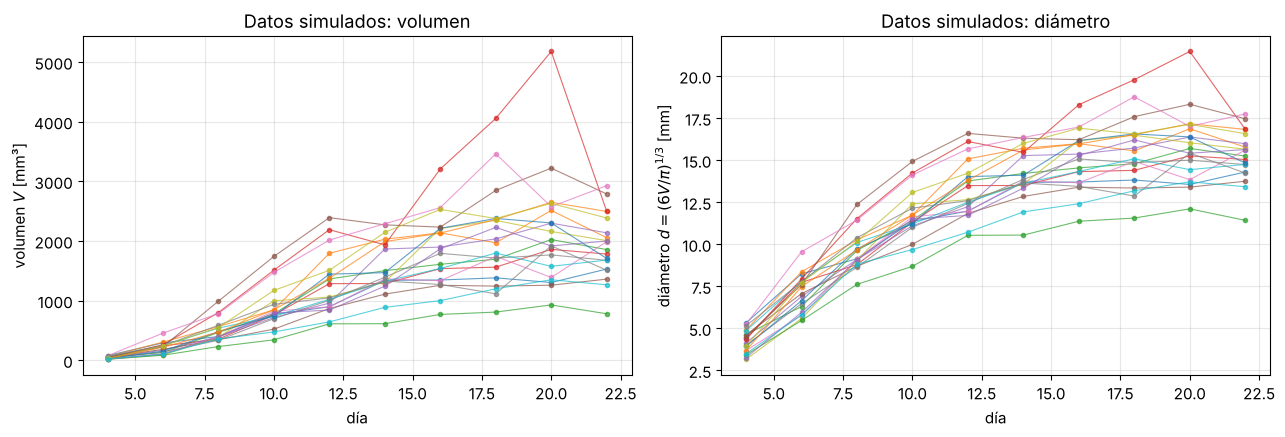

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
for i in range(n_ratones):
    axs[0].plot(dias, datos[i], "o-", ms=3, lw=0.8, alpha=0.7)
    axs[1].plot(dias, d_medido[i], "o-", ms=3, lw=0.8, alpha=0.7)
axs[0].set_ylabel("volumen $V$ [mm³]")
axs[1].set_ylabel(r"diámetro $d = (6V/\pi)^{1/3}$ [mm]")
for ax in axs:
    ax.set_xlabel("día")
axs[0].set_title("Datos simulados: volumen")
axs[1].set_title("Datos simulados: diámetro")
plt.tight_layout()
plt.show()

### Cálculos con $K_d = 15$ mm, $a = 0.25$ día⁻¹ y $d_0 = 4$ mm

Despejando el tiempo de la solución de Gompertz: $\ln\frac{d}{K_d} = \ln\frac{d_0}{K_d}\,e^{-at}$, de donde

$$
t(d) = -\frac{1}{a}\ln\!\left(\frac{\ln(d/K_d)}{\ln(d_0/K_d)}\right).
$$

(i) Duplicar el diámetro es llegar a $d = 2d_0 = 8$ mm. (ii) Llegar a 10 mm es $d = 10$. (iii) La velocidad máxima es $aK_d/e$ y ocurre cuando $d = K_d/e$, es decir cuando $\ln(d/K_d) = -1$, en $t = \frac{1}{a}\ln\ln(K_d/d_0)$.

In [5]:
Kd_, a_, d0_ = KD_REP, A_REP, D0_REP


def tiempo_para(d_meta, d0=d0_, a=a_, Kd=Kd_):
    """Días que tarda Gompertz en ir de d0 a d_meta (requiere d0 < d_meta < Kd)."""
    return -np.log(np.log(d_meta / Kd) / np.log(d0 / Kd)) / a


t_dup = tiempo_para(2 * d0_)
t_10 = tiempo_para(10.0)
d_max = Kd_ / np.e
v_max = a_ * Kd_ / np.e
t_vmax = tiempo_para(d_max)
print(f"(i)   duplicar el diámetro (4 -> 8 mm):  {t_dup:.2f} días")
print(f"(ii)  llegar a 10 mm:                    {t_10:.2f} días")
print(f"(iii) velocidad máxima = a Kd / e =      {v_max:.3f} mm/día")
print(f"      ocurre cuando d = Kd / e =         {d_max:.2f} mm, en t = {t_vmax:.2f} días")
print(f"\nComparación: la velocidad inicial es a d0 ln(Kd/d0) = {v_gompertz(d0_, a_, Kd_):.3f} mm/día;")
print(f"el tiempo de duplicación del modelo exponencial con la misma tasa inicial sería "
      f"ln 2 / (a ln(Kd/d0)) = {np.log(2) / (a_ * np.log(Kd_ / d0_)):.2f} días.")
print(f"Gompertz tarda más ({t_dup:.2f} días) porque ya está desacelerando.")

(i)   duplicar el diámetro (4 -> 8 mm):  2.97 días
(ii)  llegar a 10 mm:                    4.73 días
(iii) velocidad máxima = a Kd / e =      1.380 mm/día
      ocurre cuando d = Kd / e =         5.52 mm, en t = 1.12 días

Comparación: la velocidad inicial es a d0 ln(Kd/d0) = 1.322 mm/día;
el tiempo de duplicación del modelo exponencial con la misma tasa inicial sería ln 2 / (a ln(Kd/d0)) = 2.10 días.
Gompertz tarda más (2.97 días) porque ya está desacelerando.


### (iv) Los tres modelos durante 30 días

Para que la comparación sea justa elegimos parámetros "comparables": los tres modelos parten de $d_0 = 4$ mm **con la misma velocidad inicial** que Gompertz. Así, $k = a d_0\ln(K_d/d_0)$ (mm/día) y $\lambda = a\ln(K_d/d_0)$ (día⁻¹). Sobre las curvas ponemos los datos simulados, con $t = \text{día} - 4$.

k = 1.322 mm/día,  lambda = 0.330 1/día


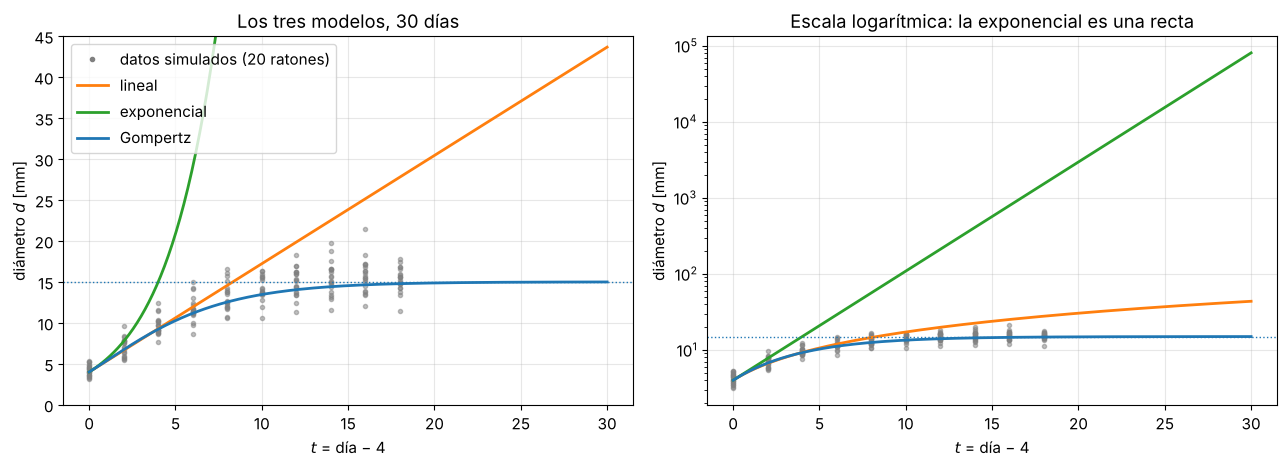

lineal      : error cuadrático medio contra la mediana de los datos =   5.78 mm
exponencial : error cuadrático medio contra la mediana de los datos = 557.22 mm
Gompertz    : error cuadrático medio contra la mediana de los datos =   0.63 mm


In [6]:
k_ = a_ * d0_ * np.log(Kd_ / d0_)      # misma velocidad inicial (mm/día)
lam_ = a_ * np.log(Kd_ / d0_)          # misma tasa per cápita inicial (1/día)
print(f"k = {k_:.3f} mm/día,  lambda = {lam_:.3f} 1/día")

t = np.linspace(0, 30, 400)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.8))
for ax in axs:
    for i in range(n_ratones):
        ax.plot(dias - 4, d_medido[i], "o", color="gray", ms=3, alpha=0.5)
    ax.plot([], [], "o", color="gray", ms=3, label="datos simulados (20 ratones)")
    ax.plot(t, d_lineal(t, d0_, k_), "C1", lw=2, label="lineal")
    ax.plot(t, d_exponencial(t, d0_, lam_), "C2", lw=2, label="exponencial")
    ax.plot(t, d_gompertz(t, d0_, a_, Kd_), "C0", lw=2, label="Gompertz")
    ax.axhline(Kd_, color="C0", ls=":", lw=1)
    ax.set_xlabel("$t$ = día − 4")
    ax.set_ylabel("diámetro $d$ [mm]")
axs[0].set_ylim(0, 45)
axs[0].set_title("Los tres modelos, 30 días")
axs[0].legend(loc="upper left")
axs[1].set_yscale("log")
axs[1].set_title("Escala logarítmica: la exponencial es una recta")
plt.tight_layout()
plt.show()

# Error de cada modelo (con los parámetros del enunciado, sin ajustar) contra
# la mediana de los datos de cada día.
mediana = np.median(d_medido, axis=0)
for nombre, curva in [("lineal", d_lineal(dias - 4, d0_, k_)),
                      ("exponencial", d_exponencial(dias - 4, d0_, lam_)),
                      ("Gompertz", d_gompertz(dias - 4, d0_, a_, Kd_))]:
    rmse = np.sqrt(np.mean((curva - mediana) ** 2))
    print(f"{nombre:12s}: error cuadrático medio contra la mediana de los datos = {rmse:6.2f} mm")

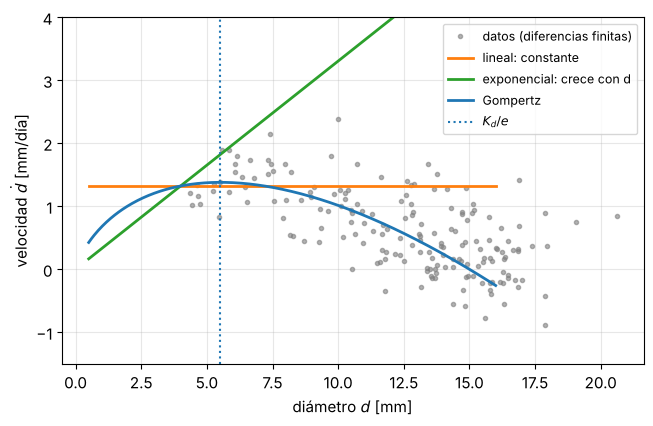

In [7]:
# Velocidad de crecimiento contra tamaño: la forma más directa de ver la
# desaceleración. En los datos la estimamos con diferencias finitas.
fig, ax = plt.subplots(figsize=(7.5, 4.5))
vel = np.diff(d_medido, axis=1) / np.diff(dias)          # mm/día entre mediciones
d_med = (d_medido[:, 1:] + d_medido[:, :-1]) / 2          # diámetro en el punto medio
ax.plot(d_med.ravel(), vel.ravel(), ".", color="gray", alpha=0.6, label="datos (diferencias finitas)")
dd = np.linspace(0.5, 16, 300)
ax.plot(dd, np.full_like(dd, k_), "C1", lw=2, label="lineal: constante")
ax.plot(dd, lam_ * dd, "C2", lw=2, label="exponencial: crece con d")
ax.plot(dd, v_gompertz(dd, a_, Kd_), "C0", lw=2, label="Gompertz")
ax.axvline(d_max, color="C0", ls=":", label=r"$K_d/e$")
ax.set_xlabel("diámetro $d$ [mm]")
ax.set_ylabel("velocidad $\\dot d$ [mm/día]")
ax.set_ylim(-1.5, 4)
ax.legend(fontsize=9)
plt.show()

**¿Cuál reproduce la desaceleración?** Solo Gompertz. El modelo lineal predice velocidad constante y el exponencial una velocidad que crece con el tamaño; en los datos la velocidad es máxima en los tumores pequeños (de 5 a 7 mm, cerca de $K_d/e$) y cae hacia cero conforme el tumor se acerca a unos 15 mm. Con los parámetros del enunciado, sin ajustar nada, Gompertz sigue la mediana de los datos con un error de menos de un milímetro, mientras que los otros dos se separan rápidamente después de la primera semana.

(Advertencia sobre la circularidad: nuestros datos se **generaron** con Gompertz, así que este resultado era de esperarse. Con los datos reales de Benzekry et al. la conclusión del artículo es la misma, Gompertz y modelos similares describen bien las curvas, pero vale la pena repetir el ejercicio con ellos.)

## 4. Discusión

**(i) ¿Por qué desaceleran los tumores reales?** Varias razones actúan a la vez:

* **Hipoxia y difusión limitada:** el oxígeno y los nutrientes penetran solo unos 100–200 μm desde un vaso sanguíneo; en un tumor grande las células del centro reciben poco y dejan de dividirse.
* **Necrosis:** las células más lejanas mueren; el núcleo necrótico ocupa volumen sin aportar crecimiento.
* **Limitación vascular:** la angiogénesis no siempre alcanza a irrigar todo el tumor, y los vasos tumorales son desordenados e ineficientes.
* **Presión mecánica y espacio:** el tejido circundante y la presión intersticial frenan la expansión.
* **Respuesta inmune:** linfocitos y macrófagos eliminan células tumorales, más cuanto mayor es el tumor.

Todas tienen el mismo efecto en el modelo: la tasa per cápita disminuye con el tamaño, que es justamente la hipótesis de Gompertz.

**(ii) Hipótesis de Norton–Simon.** Según esta hipótesis, el efecto de un tratamiento es proporcional a la velocidad de crecimiento que tendría el tumor sin tratar a ese tamaño. La respuesta depende de qué "velocidad" usemos:

* Si es la **tasa per cápita** $a\ln(K_d/d)$, que es la que determina qué **fracción** de células se elimina, el tratamiento es más eficaz cuanto **más pequeño** es el tumor: tratar lo antes posible, y no dejar que el tumor residual vuelva a crecer entre ciclos.
* Si es la **velocidad absoluta** del diámetro, $\dot d$, el máximo está en $d = K_d/e \approx 5.5$ mm.

Ojo: el punto de máxima velocidad absoluta **depende de la variable que midamos**. Para el volumen, $\dot V$ es máxima cuando $V = K/e$, es decir cuando $d = K_d\,e^{-1/3} \approx 10.7$ mm, no 5.5 mm. La invariancia de la sección 2 se refiere a la tasa $a$, no al punto de inflexión. La lectura per cápita es la que no depende de esa elección y es la que tiene una interpretación directa como fracción eliminada. Esta línea de razonamiento es la que motivó los esquemas de quimioterapia de "dosis densa" (ciclos más frecuentes).

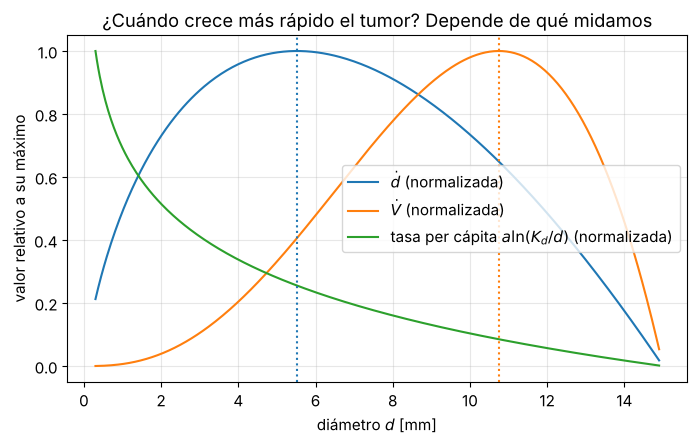

In [8]:
# Velocidad absoluta del diámetro y del volumen, y tasa per cápita, contra el diámetro.
dd = np.linspace(0.3, 14.9, 400)
V_dd = np.pi / 6 * dd**3
K_V = np.pi / 6 * Kd_**3
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(dd, v_gompertz(dd, a_, Kd_) / v_gompertz(Kd_ / np.e, a_, Kd_), label=r"$\dot d$ (normalizada)")
vV = a_ * V_dd * np.log(K_V / V_dd)
ax.plot(dd, vV / vV.max(), label=r"$\dot V$ (normalizada)")
tasa = a_ * np.log(Kd_ / dd)
ax.plot(dd, tasa / tasa.max(), label=r"tasa per cápita $a\ln(K_d/d)$ (normalizada)")
ax.axvline(Kd_ / np.e, color="C0", ls=":")
ax.axvline(Kd_ * np.exp(-1 / 3), color="C1", ls=":")
ax.set_xlabel("diámetro $d$ [mm]")
ax.set_ylabel("valor relativo a su máximo")
ax.set_title("¿Cuándo crece más rápido el tumor? Depende de qué midamos")
ax.legend()
plt.show()

**(iii) Cáncer de mama humano (Spratt, 1993).** Que los diámetros medidos por mamografía en tumores humanos también sigan una dinámica de Gompertz sugiere que:

* La desaceleración **no es un artefacto** de los modelos de ratón: es una propiedad general del crecimiento de tumores sólidos.
* Cuando un tumor se detecta clínicamente (alrededor de 1 cm, unas $10^9$ células) ya pasó buena parte de su historia; la fase de crecimiento per cápita más rápido ocurrió cuando era indetectable. Si se extrapola hacia atrás con un modelo exponencial usando la tasa medida al momento del diagnóstico (que ya es lenta), se **sobreestima** la edad del tumor: en realidad creció mucho más rápido cuando era pequeño. La forma de la curva importa para estimar desde cuándo existe.
* Las tasas per cápita son mayores en tumores pequeños, así que los tumores detectados temprano (por tamizaje) no solo son más pequeños, también podrían ser más sensibles a tratamientos que actúan sobre células en división (en la lógica de Norton–Simon).
* Permite predecir el crecimiento de un tumor a partir de pocas mediciones y comparar tumores con un par de parámetros ($a$, $K_d$).

**Referencias:** Gompertz (1825); Laird (1964), *Br. J. Cancer* 18: 490–497; Norton & Simon (1977), *Cancer* 31: 572–578; Benzekry et al. (2014), *PLoS Comput. Biol.* 10: e1003800; Vaghi et al. (2020), *PLoS Comput. Biol.* 16: e1007178; Spratt (1993), *Cancer* 71: 2013–2019.